In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit

def set_random_rho(ff):
    '''
    Proton Density.
    rho_tot = total proton density
    '''
    rho_fat = np.random.rand()
    rho_water = (rho_fat/ff)-rho_fat
    return(rho_fat, rho_water)


def set_rho(ff, rho_tot):
    '''
    Proton Density.
    rho_tot = total proton density
    '''
    rho_fat = ff*rho_tot
    rho_water = rho_tot - rho_fat
    return(rho_fat, rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    
    # TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    return(echo_times)


def gen_GRE(echo_times, rho_fat, rho_water, t2fat_13ppm=0.062, t2water_47ppm=0.023):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs (absolute signal intensity) (equivalent to ydata)
    '''
    
    # rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    rho = np.array([rho_fat*0.047, rho_fat*0.039, rho_fat*0.006, 
                    rho_fat*0.12, rho_fat*0.7, rho_fat*0.088, rho_water])
    
    # standard, individual T2* values
    t2star = np.array([0.030, 0.040, 0.051, 0.052, t2fat_13ppm, 0.083, t2water_47ppm] )
    
    # frequency in parts per million for each moiety
    freq_ppm = np.array([5.3, 4.2, 2.75, 2.1, 1.3, 0.9, 4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      # magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) # Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    # calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    # obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return(Sabs)

def gen_GRE_noise(echo_times, rho_fat, rho_water, t2fat_13ppm=0.062, t2water_47ppm=0.023, noise_level=0.01):
    '''
    NEEDS REVIEW
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
                t2star     -> array >0, T2* values for fat peaks at 5.3, 4.2, 2.75, 2.1, 1.3 and 0.9 ppm (fat) and water
                noise_sd   -> float >0, noise standard deviation as proportion of the first signal point intensity (default is 1% = 0.01)
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
# rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    rho = np.array([rho_fat*0.047, rho_fat*0.039, rho_fat*0.006, 
                    rho_fat*0.12, rho_fat*0.7, rho_fat*0.088, rho_water])
    
    # standard, individual T2* values
    t2star = np.array([0.030, 0.040, 0.051, 0.052, t2fat_13ppm, 0.083, t2water_47ppm] )
    
    # frequency in parts per million for each moiety
    freq_ppm = np.array([5.3, 4.2, 2.75, 2.1, 1.3, 0.9, 4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      # magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) # Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    # calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
        
    #obtain sum & add noise
    Ssum= (len(echo_times))
    Ssum=np.zeros(Ssum,dtype='complex')
    Ssum = np.sum(S, axis=0)
    
    for t,TE in enumerate(echo_times):
        Ssum[t] = Ssum[t].real+Ssum[0].real*noise_level*np.random.normal()+1j*(Ssum[t].imag+Ssum[0].imag*noise_level*np.random.normal())
 
    #obtain absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    Sabs = np.absolute(Ssum)
    return (Sabs)



def continuous_timeseries(endpoint=0.01):
    return(np.linspace(0, endpoint, 1000, endpoint=True))

def calc_fatfrac(fitted_parameters):
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return(ff)

In [2]:
import arff

def calc_dist_angle(p0,p1):
    #funciona para pontos dentro do dominio x:[0,1], y:[0,1] (supondo o sinal de modulo normalizado pela norma de frobenius)
    
    #gera 2 pontos de TE e subtrai o primeiro do segundo (obter a base de tempo)
    #o multiplicador de 1000 lineariza a função cosseno (verificar essa explicação!)
    time = 1000*(discrete_timeseries(2))[1]-(discrete_timeseries(2))[0] 
        
    #como não é um triângulo retângulo, vamos usar a lei dos cossenos para obter o ângulo
    #e a distância sai junto
    #para o ângulo a referência de zero grau é a posição 12 horas, paralela ao eixo y

    #obtem lados do triângulo, valor 2 foi usado como altura total em a e b para não dar erro quando p0=1 
    a = np.sqrt(np.square(2-p1)+np.square(time)) #a corresponde ao lado superior
    b = 2-p0 #b corresponde ao lado paralelo ao eixo y
    c = np.sqrt(np.square(p0-p1)+np.square(time)) #c corresponde ao lado que conecta os pontos p0 e p1

    distance = c
    cosA = (np.square(b)+np.square(c)-np.square(a))/(2*b*c) #lei dos cossenos
    theta_rad = np.arccos(cosA)

    #a função deve retornar a distância e ângulo normalizados entre 0 e 1. Uma função normalizada assim é dada por:
    # F(x)[0,1] = (f(x)-min(f(x)))/(max(f(x)-min(f(x)))
    #precisamos então calcular as valores de de distância e ângulo nos extremos.

    #valor minimo que a distancia pode atingir    
    dist_min = time
    #valor máximo que a distancia pode atingir
    dist_max = np.sqrt(1+np.square(time)) 
    #normalização
    dist_norm = (distance-dist_min)/(dist_max-dist_min)

    #para normalizar o ângulo, calcula-se o menor e maior valor do ângulo
    #o menor ocorre quando (p0,p1) = (0,1)
    p0_min = 0
    p1_min = 1
    a_min = np.sqrt(np.square(2-p1_min)+np.square(time)) #a corresponde ao lado superior
    b_min = 2-p0_min #b corresponde ao lado paralelo ao eixo y
    c_min = np.sqrt(np.square(p0_min-p1_min)+np.square(time)) #c corresponde ao lado que conecta os pontos p0 e p1

    cosA_min = (np.square(b_min)+np.square(c_min)-np.square(a_min))/(2*b_min*c_min) #lei dos cossenos
    theta_min = np.arccos(cosA_min)
    #o maior ocorre quando (p0,p1) = (1,0)
    #o cálculo do maior valor pode ser obtido subtraindo 180 graus do resultado do menor ângulo
    theta_max = np.pi-theta_min
    #normalização
    theta_rad_norm = (theta_rad-theta_min)/(theta_max-theta_min)
       
    return dist_norm, theta_rad_norm

def make_FF_arff(dataset):
    #import arff
    obj = {
   'description': u'distance, angle and fat fraction',
   'relation': 'fat fraction ml',
   'attributes': [
       ('distance 1-2', 'REAL'),
       ('angle 1-2', 'REAL'),
       ('distance 2-3', 'REAL'),
       ('angle 2-3', 'REAL'),
       ('distance 3-4', 'REAL'),
       ('angle 3-4', 'REAL'),
       ('distance 4-5', 'REAL'),
       ('angle 4-5', 'REAL'),
       ('distance 5-6', 'REAL'),
       ('angle 5-6', 'REAL'),
       ('distance 6-7', 'REAL'),
       ('angle 6-7', 'REAL'),
       ('fat fraction', 'REAL'),
   ],
   'data': dataset,
    }
    return obj



In [3]:
def fit_multiinterf(echo_times, rho_fat, rho_water, t2star):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    
    echo_times = np.array(echo_times)
    rho_fat = np.array(rho_fat)
    rho_water = np.array(rho_water)
    t2star = np.array(t2star)
    
    #cn is the fractional proton density of each fat moiety (Yokoo) (see freq_ppm)
    cn = np.array([0.12, 0.7, 0.088,]) 
    
    #frequency in parts per million for each fat moiety
    ppm_fat = np.array([2.1, 1.3, 0.9])
    ppm_water = np.array(4.7)
    
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    freq_water = np.array(ppm_water*magField*hydroGyro/1e6) #water frequency in Hertz
    
    #relative frequency for each fat to that of water
    freqr_fat = np.zeros(len(ppm_fat))
    for n, fppm in enumerate(ppm_fat):
        freqr_fat[n] = freq_water-(fppm*magField*hydroGyro/1e6)
    
    #calculate the signal for each moiety    
    S = (len(freqr_fat),len(echo_times))
    S = np.zeros(S,dtype='complex')
        #three fat signals
    for n, moieties in enumerate(freqr_fat):
        for t,TE in enumerate(echo_times):
            S[n,t] = cn[n]*np.exp(2.0*np.pi*1j*freqr_fat[n]*TE)
    
    Ssum= len(echo_times)
    Ssum = np.zeros(Ssum)
    Ssum = np.sum(S, axis=0) #sum of fat signals
    Sabs = np.absolute(rho_water + rho_fat*Ssum) #multiply rho_fat and add rho_water, take absolute value
    Sfinal = len(echo_times)
    Sfinal = np.zeros(Sfinal)
    for t,TE in enumerate(echo_times):
        Sfinal[t] = Sabs[t]*np.exp(-TE/t2star) #exponential decay
    
    return (Sfinal)

def calc_fatfrac(fitted_parameters):
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return(ff)

### Gerar dataset com T2* variável, sem ruído

In [3]:
#gerar dataset com curvas de 0 a 100% de gordura com t2* variável, sem ruído 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)

ff = np.linspace(0.01, 1.0, num=1000) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=10) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=10) # t2* water, valores originais = [0.031, 0.041], hamilton
total_size = len(ff)*len(t2fat)*len(t2water)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T

n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
            signal = gen_GRE(xdata, rho_fat, rho_water, t2f, t2w) #obter sinal GRE com t2* fixos, sem ruído
            signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
            signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
            n = n+1

for (x,y) in np.ndindex(signal_norm_collection.shape): #x: linha, y: col
    if  y+1==7: #não calcular ultima coluna
        pass
    else:
        distance_collection[x,y], theta_collection[x,y] = calc_dist_angle(signal_norm_collection[x,y],signal_norm_collection[x,y+1])

ff_collection = (np.dstack((distance_collection,theta_collection))) #junta os dados 
ff_collection = np.reshape(ff_collection,(total_size,12)) #redimensiona a matriz
ff_collection = np.c_[ff_collection,ff_repeat]

ff_arff = make_FF_arff(ff_collection)
ff_arff = arff.dumps(ff_arff)

fo = open("testarff.arff", "w+")
fo.write(ff_arff)

# Close file
fo.close()


### Dataset T2* variável + ruído

In [11]:
#gerar dataset com curvas de 0 a 100% de gordura com t2* variável, com ruído 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)
snr = 30
ff = np.linspace(0.01, 1.0, num=450) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=6) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=6) # t2* water, valores originais = [0.031, 0.041], hamilton
noise = np.repeat(1/snr, 5)

total_size = len(ff)*len(t2fat)*len(t2water)*len(noise)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)*len(noise)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T

n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            for noise_level in noise:
                rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
                signal = gen_GRE_noise(xdata, rho_fat, rho_water, t2f, t2w, noise_level) #obter sinal GRE com t2* fixos, com ruído
                signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
                signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
                n = n+1

for (x,y) in np.ndindex(signal_norm_collection.shape): #x: linha, y: col
    if  y+1==7: #não calcular ultima coluna
        pass
    else:
        distance_collection[x,y], theta_collection[x,y] = calc_dist_angle(signal_norm_collection[x,y],signal_norm_collection[x,y+1])

ff_collection = (np.dstack((distance_collection,theta_collection))) #junta os dados 
ff_collection = np.reshape(ff_collection,(total_size,12)) #redimensiona a matriz
ff_collection = np.c_[ff_collection,ff_repeat]

ff_arff = make_FF_arff(ff_collection)
ff_arff = arff.dumps(ff_arff)


fo = open("dataset_snr"+str(snr)+"_"+str(total_size)+".arff", "w+")
fo.write(ff_arff)

# Close file
fo.close()


### Dataset T2* variável com ruído variável

In [13]:
#gerar dataset com curvas de 0 a 100% de gordura com t2* variável, com ruído 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)
snr = 'Variavel'
ff = np.linspace(0.01, 1.0, num=450) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=6) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=6) # t2* water, valores originais = [0.031, 0.041], hamilton
noise = [0, 0.025, 0.05, 0.075, 0.1] #SNR = 40, 20, 13,3, 10

total_size = len(ff)*len(t2fat)*len(t2water)*len(noise)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)*len(noise)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T

n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            for noise_level in noise:
                rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
                signal = gen_GRE_noise(xdata, rho_fat, rho_water, t2f, t2w, noise_level) #obter sinal GRE com t2* fixos, com ruído
                signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
                signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
                n = n+1

for (x,y) in np.ndindex(signal_norm_collection.shape): #x: linha, y: col
    if  y+1==7: #não calcular ultima coluna
        pass
    else:
        distance_collection[x,y], theta_collection[x,y] = calc_dist_angle(signal_norm_collection[x,y],signal_norm_collection[x,y+1])

ff_collection = (np.dstack((distance_collection,theta_collection))) #junta os dados 
ff_collection = np.reshape(ff_collection,(total_size,12)) #redimensiona a matriz
ff_collection = np.c_[ff_collection,ff_repeat]

ff_arff = make_FF_arff(ff_collection)
ff_arff = arff.dumps(ff_arff)


fo = open("dataset_snr"+str(snr)+"_"+str(total_size)+".arff", "w+")
fo.write(ff_arff)

# Close file
fo.close()


## multi-interferencia

### 0 a 100% de gordura com t2* variável, sem ruido

correlation coeff (0.087509610204764832, 1.8399786148798029e-18)
mean absolute error 0.224685233851
root mean squared error 0.383685783435


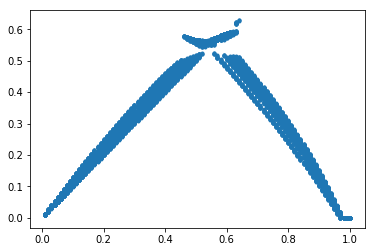

In [48]:
#gerar dataset com 1000 curvas de 0 a 100% de gordura com t2* variável 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)
from scipy.stats.stats import pearsonr
import sklearn.metrics as mtr

ff = np.linspace(0.01, 1.0, num=100) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=10) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=10) # t2* water, valores originais = [0.031, 0.041], hamilton
total_size = len(ff)*len(t2fat)*len(t2water)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T


n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
            signal = gen_GRE(xdata, rho_fat, rho_water, t2f, t2w) #obter sinal GRE com t2* fixos, sem ruído
            signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
            signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
            n = n+1

            
#calcula multi-interferencia
res_multi = []
bd = (0, [np.inf, np.inf, 1])
for element in signal_norm_collection:
    fitted_par, pcov = curve_fit(fit_multiinterf, xdata, element, bounds=bd)
    res_multi.append(calc_fatfrac(fitted_par))

print ('correlation coeff', pearsonr(res_multi, ff_repeat))
print ('mean absolute error', mtr.mean_absolute_error(ff_repeat, res_multi))
print ('root mean squared error', np.sqrt(mtr.mean_squared_error(ff_repeat, res_multi)))    
    
plt.plot(ff_repeat, res_multi, '.')
plt.show()



### 0 a 45% de gordura com t2* variável, sem ruido


correlation coeff (0.99487255837123734, 0.0)
mean absolute error 0.0151596527656
root mean squared error 0.021090427025


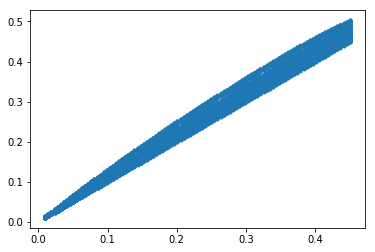

In [42]:
#gerar dataset com 1000 curvas de 0 a 45% de gordura com t2* variável 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)
from scipy.stats.stats import pearsonr
import sklearn.metrics as mtr

ff = np.linspace(0.01, 0.45, num=100) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=10) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=10) # t2* water, valores originais = [0.031, 0.041], hamilton
total_size = len(ff)*len(t2fat)*len(t2water)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T


n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
            signal = gen_GRE(xdata, rho_fat, rho_water, t2f, t2w) #obter sinal GRE com t2* fixos, sem ruído
            signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
            signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
            n = n+1

            
#calcula multi-interferencia
res_multi = []
bd = (0, [np.inf, np.inf, 1])
for element in signal_norm_collection:
    fitted_par, pcov = curve_fit(fit_multiinterf, xdata, element, bounds=bd)
    res_multi.append(calc_fatfrac(fitted_par))

print ('correlation coeff', pearsonr(res_multi, ff_repeat))
print ('mean absolute error', mtr.mean_absolute_error(ff_repeat, res_multi))
print ('root mean squared error', np.sqrt(mtr.mean_squared_error(ff_repeat, res_multi)))

plt.plot(ff_repeat, res_multi, '.')
plt.show()


### 0 a 45% de gordura com t2* variável, com ruido = 3% (SNR = 33.3)


correlation coeff (0.99340990815822006, 0.0)
mean absolute error 0.0168613598251
root mean squared error 0.0222551120714


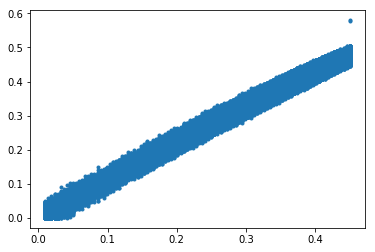

In [58]:
#gerar dataset com 1000 curvas de 0 a 45% de gordura com t2* variável 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)
from scipy.stats.stats import pearsonr
import sklearn.metrics as mtr

snr = 33.3
ff = np.linspace(0.01, 0.45, num=100) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=10) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=10) # t2* water, valores originais = [0.031, 0.041], hamilton
noise = np.repeat(1/snr, 10)

total_size = len(ff)*len(t2fat)*len(t2water)*len(noise)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)*len(noise)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T

n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            for noise_level in noise:
                rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
                signal = gen_GRE_noise(xdata, rho_fat, rho_water, t2f, t2w, noise_level) #obter sinal GRE com t2* fixos, com ruído
                signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
                signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
                n = n+1

#calcula multi-interferencia
res_multi = []
bd = (0, [np.inf, np.inf, 1])
for element in signal_norm_collection:
    fitted_par, pcov = curve_fit(fit_multiinterf, xdata, element, bounds=bd)
    res_multi.append(calc_fatfrac(fitted_par))

print ('correlation coeff', pearsonr(res_multi, ff_repeat))
print ('mean absolute error', mtr.mean_absolute_error(ff_repeat, res_multi))
print ('root mean squared error', np.sqrt(mtr.mean_squared_error(ff_repeat, res_multi)))

plt.plot(ff_repeat, res_multi, '.')
plt.show()


### 0 a 40% de gordura com t2* variável, com ruido = 5% (SNR = 20)


correlation coeff (0.98714509984294174, 0.0)
mean absolute error 0.0193780176686
root mean squared error 0.0252253417228


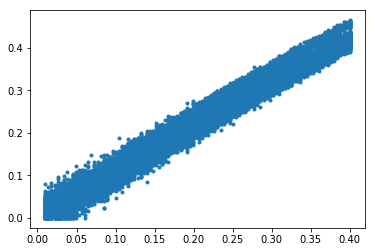

In [12]:
#gerar dataset com 1000 curvas de 0 a 40% de gordura com t2* variável 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)
from scipy.stats.stats import pearsonr
import sklearn.metrics as mtr

snr = 20
ff = np.linspace(0.01, 0.40, num=100) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=6) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=6) # t2* water, valores originais = [0.031, 0.041], hamilton
noise = np.repeat(1/snr, 5)

total_size = len(ff)*len(t2fat)*len(t2water)*len(noise)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)*len(noise)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T

n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            for noise_level in noise:
                rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
                signal = gen_GRE_noise(xdata, rho_fat, rho_water, t2f, t2w, noise_level) #obter sinal GRE com t2* fixos, com ruído
                signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
                signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
                n = n+1

#calcula multi-interferencia
res_multi = []
bd = (0, [np.inf, np.inf, 1])
for element in signal_norm_collection:
    fitted_par, pcov = curve_fit(fit_multiinterf, xdata, element, bounds=bd)
    res_multi.append(calc_fatfrac(fitted_par))

print ('correlation coeff', pearsonr(res_multi, ff_repeat))
print ('mean absolute error', mtr.mean_absolute_error(ff_repeat, res_multi))
print ('root mean squared error', np.sqrt(mtr.mean_squared_error(ff_repeat, res_multi)))

plt.plot(ff_repeat, res_multi, '.')
plt.show()


### 0 a 45% de gordura com t2* variável, com ruido = 10% (SNR = 10)


correlation coeff (0.98060064343895148, 0.0)
mean absolute error 0.0243259189148
root mean squared error 0.0307667334877


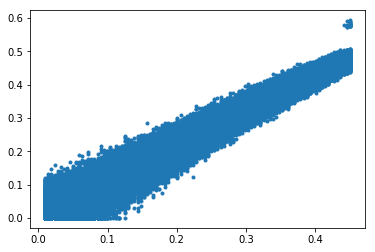

In [60]:
#gerar dataset com 1000 curvas de 0 a 45% de gordura com t2* variável 
#e obter os parâmetros R (distância entre pontos) e T (ângulo entre pontos)
from scipy.stats.stats import pearsonr
import sklearn.metrics as mtr

snr = 10
ff = np.linspace(0.01, 0.45, num=100) # fat fraction
t2fat =  np.linspace(0.05, 0.1, num=10) # t2* fat @1.3ppm, valores originais = [0.059, 0.098]
t2water = np.linspace(0.01, 0.05, num=10) # t2* water, valores originais = [0.031, 0.041], hamilton
noise = np.repeat(1/snr, 10)

total_size = len(ff)*len(t2fat)*len(t2water)*len(noise)
ff_repeat = np.repeat(ff,len(t2fat)*len(t2water)*len(noise)) #repete ff para preencher a lista

signal_norm_collection = np.zeros([total_size,7]) #sinal normalizado
distance_collection = np.zeros([total_size,6]) #6 distancias
theta_collection = np.zeros([total_size,6]) #6 angulos
xdata = discrete_timeseries(7) #gerar TEs para 3T

n=0
for fat_fraction in ff:
    for t2f in t2fat:
        for t2w in t2water:
            for noise_level in noise:
                rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
                signal = gen_GRE_noise(xdata, rho_fat, rho_water, t2f, t2w, noise_level) #obter sinal GRE com t2* fixos, com ruído
                signal_norm = signal/np.linalg.norm(signal) #normalizar os sinais, norma de frobenius
                signal_norm_collection[n,:] = signal_norm #colocar os sinais numa coleção, pontos 0:6
                n = n+1

#calcula multi-interferencia
res_multi = []
bd = (0, [np.inf, np.inf, 1])
for element in signal_norm_collection:
    fitted_par, pcov = curve_fit(fit_multiinterf, xdata, element, bounds=bd)
    res_multi.append(calc_fatfrac(fitted_par))

print ('correlation coeff', pearsonr(res_multi, ff_repeat))
print ('mean absolute error', mtr.mean_absolute_error(ff_repeat, res_multi))
print ('root mean squared error', np.sqrt(mtr.mean_squared_error(ff_repeat, res_multi)))

plt.plot(ff_repeat, res_multi, '.')
plt.show()

### Testes

In [ ]:
import arff

obj = {
    u'attributes': [
        (u'outlook', [u'sunny', u'overcast', u'rainy']),
        (u'temperature', u'REAL'),
        (u'humidity', u'REAL'),
        (u'windy', [u'TRUE', u'FALSE']),
        (u'play', [u'yes', u'no'])],
    u'data': [
        [u'sunny', 85.0, 85.0, u'FALSE', u'no'],
        [u'sunny', 80.0, 90.0, u'TRUE', u'no'],
        [u'overcast', 83.0, 86.0, u'FALSE', u'yes'],
        [u'rainy', 70.0, 96.0, u'FALSE', u'yes'],
        [u'rainy', 68.0, 80.0, u'FALSE', u'yes'],
        [u'rainy', 65.0, 70.0, u'TRUE', u'no'],
        [u'overcast', 64.0, 65.0, u'TRUE', u'yes'],
        [u'sunny', 72.0, 95.0, u'FALSE', u'no'],
        [u'sunny', 69.0, 70.0, u'FALSE', u'yes'],
        [u'rainy', 75.0, 80.0, u'FALSE', u'yes'],
        [u'sunny', 75.0, 70.0, u'TRUE', u'yes'],
        [u'overcast', 72.0, 90.0, u'TRUE', u'yes'],
        [u'overcast', 81.0, 75.0, u'FALSE', u'yes'],
        [u'rainy', 71.0, 91.0, u'TRUE', u'no']
    ],
    u'description': u'',
    u'relation': u'weather'
}
print (arff.dumps(obj))

In [35]:
print( np.repeat(10, 10))

[10 10 10 10 10 10 10 10 10 10]


In [ ]:
from collections import deque
#daf = zip(distance_collection, )
#ff [1,10]
#distance_collection [10,6]
#theta_collection [10,6]
#for (x,y) in np.ndindex(signal_norm_collection.shape): #x: linha, y: col
outp = (np.dstack((distance_collection,theta_collection)))
outp_reshepado = np.reshape(outp,(10,12))

print(np.c_[outp_reshepado,ff])


In [ ]:
x = np.arange(9.0)
print (x)
print (np.split(x, 3))

In [ ]:
print('segundo teste')

a = np.array([[1, 2, 3], [4,5,6], [7,8,9]])
b = np.zeros([3,3])
print (a)
for (x,y) in np.ndindex(a.shape):
     if  y+1==3:
        pass
     else:
        b[x,y] = a[x,y]+a[x,y+1]
print (b)

In [ ]:
ff = np.linspace(0.01, 1, num=10) # fat fraction
signal_norm_collection = np.zeros([len(ff),8])
distance_theta_collection = np.zeros([len(ff),13])


for n,fat_fraction in enumerate (ff):
    rho_fat, rho_water = set_random_rho(fat_fraction)
    xdata = discrete_timeseries(7)
    signal = gen_GRE(xdata, rho_fat, rho_water)
    signal_norm = signal/np.linalg.norm(signal)
    signal_norm_collection[n,0:7] = signal_norm
    signal_norm_collection[n,7] = fat_fraction
    
    
print (signal_norm_collection)

In [ ]:
deltaTime = (discrete_timeseries(2))[1]-(discrete_timeseries(2))[0]
print (deltaTime)

In [ ]:
a = 1
b = a
print (b)
b = 2
print (a)
print (b)

In [ ]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01, 0.50, num=10) # fat fraction
rho_tot = 100                 # rho_water + rho_fat
init_guess_var = np.linspace(0, 2*rho_tot) # erro para valores iniciais
noise = 0.10

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE_noise(xdata, rho_fat, rho_water, noise)

In [ ]:
a = np.array([2,3,4])
print (np.flip(a,0))

In [ ]:
print ((discrete_timeseries(2))[1]-(discrete_timeseries(2))[0])

In [ ]:
#teste da função calc_dist_angle()

p01_teste = 0.0
p02_teste = 1.0
p1_var1 = np.linspace(0.0, 1.0, num=10)
p1_var2 = np.linspace(1.0, 0.0, num=10)

theta_var1 = np.zeros(len(p1_var1))
theta_var2 = np.zeros(len(p1_var1))

c_var1 = np.zeros(len(p1_var1))
c_var2 = np.zeros(len(p1_var1))


for n,value in enumerate (p1_var1):
    c_var1[n], theta_var1[n] = calc_dist_angle(p01_teste,value)
for n,value in enumerate (p1_var2):
    c_var2[n], theta_var2[n] = calc_dist_angle(p02_teste,value)
    
p1_var_tot = np.append(np.flip(p01_teste-p1_var1,0),p02_teste-p1_var2) 
theta_var = np.append(np.flip(theta_var1,0),theta_var2)
c_var = np.append(np.flip(c_var1,0),c_var2)

    #print (theta_var[n])
#plt.plot(p1_var, a_var,'o')
#plt.plot(p1_var, b_var,'o')
plt.plot(p1_var_tot,c_var, '-')
plt.title('distancia entre p0 e p1')
plt.xlabel('p0-p1 [-1,1]')
plt.ylabel('distancia [0-1]')
plt.show()

plt.plot(p1_var_tot, theta_var,'-')
plt.title('ângulo entre eixo y e reta p0-p1')
plt.xlabel('p0-p1 [-1,1]')
plt.ylabel('ângulo [0-1]')
plt.show()
print('distance', c_var)

print ('angle', theta_var)
